In [1]:
import os
import shutil
import pandas as pd
from glob import glob
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from skimage import io
import math

# 4.1  Evaluation of application pipeline on reference dataset

This notebuc descrebes the final state of the proposed data processing pipeline in a scope of an environmental research.

In [2]:
from common.configuration import ModelPath, DatasetPath, species_invasive, species_native
from pipeline.full_predict import ImageProcessor
from common.configuration import DatasetPath, ModelPath, species_native, species_label_map_all, species_classes_map_all

In [3]:
model_class_to_c_number_remap = {}
for i, c in enumerate(species_native):
    model_class_to_c_number_remap[i] = species_classes_map_all[c]

def prediction_to_class_name(prediction):
    predicted_c_number = model_class_to_c_number_remap.get(prediction, -1)
    return species_label_map_all[predicted_c_number]

In [4]:
image_processor = ImageProcessor(ModelPath.instance_segmentation, ModelPath.osc_classification, prediction_to_class_name)

Using cache found in C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\siniz/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


### Reference samples dataset

Load test subset of full images


In [ ]:
test_set_df = pd.read_csv("Save/classification_test_set.csv", index_col=0)
test_set_df["file_name"] = test_set_df["image"].map(lambda f: os.path.split(f)[1])
test_set_df["folder"] = test_set_df["image"].map(lambda f: os.path.split(f)[0])
test_set_df["folder"] = test_set_df["folder"].map(lambda f: os.path.split(f)[1])
test_set_df["file_name"] = test_set_df["file_name"].map(lambda f: f.rsplit("_", 1)[0])
test_set_df["file_name"] = DatasetPath.raw_sample_images + "/" + test_set_df["folder"] + "/" + test_set_df["file_name"] + ".jpg"

test_set_df = test_set_df.drop_duplicates(subset=['file_name'])
# Test if all images exists
for v in test_set_df["file_name"]:
    assert os.path.exists(v), f"File {v} not exists"

test_set_df
    

,label,image,file_name,folder
0,Acer,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Acer
1,Acer,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Acer
5,Acer,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Acer
11,Acer,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Acer
12,Acer,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Acer
...,...,...,...,...
1413,Malus,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Malus
1414,Malus,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Malus
1417,Malus,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Malus
1421,Malus,Dataset/pollen_dataset_2025_02_05\reference_ds...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Malus


 Plot some samples to test dataset

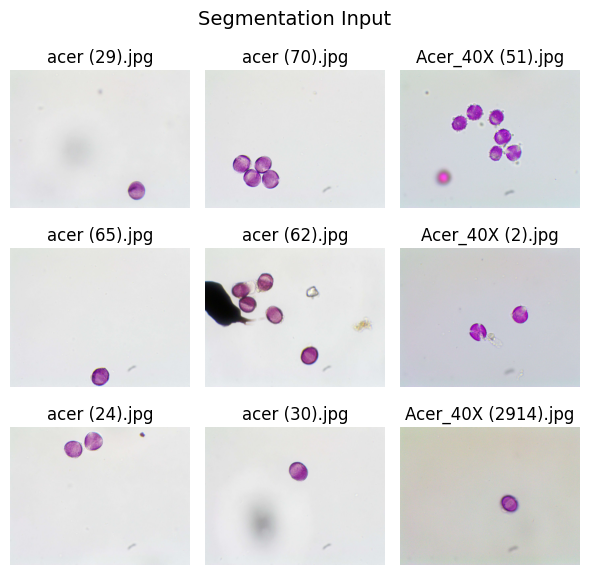

In [6]:
# Plot some samples
samples = test_set_df["file_name"][0:9]
n = math.ceil(len(samples) ** (1/2))
fig, axs = plt.subplots(nrows=n, ncols=n, figsize=(n*2, n*2))
for ax, img_path in zip(axs.flatten(), samples):
    image_rgb = io.imread(img_path)
    ax.imshow(image_rgb)
    ax.set_axis_off()
    ax.set_title(os.path.basename(img_path))
for ax in axs.flatten()[len(samples):]:
    ax.set_visible(False)
fig.suptitle('Segmentation Input', fontsize=14)
plt.tight_layout()
plt.show()

### Process all images

In [7]:
segmentation_output_dir = "Save/app_pipeline/segmentation_output_reference"

In [8]:
if os.path.exists(segmentation_output_dir):
    shutil.rmtree(segmentation_output_dir)
os.makedirs(segmentation_output_dir, exist_ok=False)

### Perform predictions

In [9]:
predictions_path = "Save/reference_predictions.csv"

In [10]:
if not os.path.exists(predictions_path):
    obj_stats = {}

    predictions = []
    for image_path, label in tqdm(zip(test_set_df["file_name"], test_set_df["label"])):
        pred_labels = image_processor.process_image(image_path=image_path,
                                                    crops_path=segmentation_output_dir,
                                                    augment = 0,
                                                    with_embeddings=True)
        for pred_class in pred_labels:
            prediction = {}
            prediction["label"] = label
            prediction["prediction"] = pred_class[0]
            prediction["embeddings"] = pred_class[1]
            prediction["image"] = image_path
            predictions.append(prediction)
    predictions_df = pd.DataFrame(predictions)
    predictions_df.to_csv(predictions_path)

0it [00:00, ?it/s]

f:\Research\Automatic online monitoring of allergic pollen\Pollen-Analyzer\common\osc_classification.py:88: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3641.)
  scores[range(scores.shape[0]), candidate.T] < threshold, candidate, -1)


0 is duplicate of 5
7 is duplicate of 1
1 is duplicate of 2
0 is duplicate of 1
2 is duplicate of 0
6 is duplicate of 7
2 is duplicate of 0
1 is duplicate of 3
0 is duplicate of 1
0 is duplicate of 2
2 is duplicate of 0
1 is duplicate of 0
4 is duplicate of 1
1 is duplicate of 5
3 is duplicate of 2
5 is duplicate of 1
4 is duplicate of 2
3 is duplicate of 1
0 is duplicate of 1
